Use this dataset for this assignment: https://docs.google.com/spreadsheets/d/1v0SoHvdro_Jm_3eNMBEO16X6wNDFigi9EGycsECS_Lo/pub?output=csv

In [1]:
import tensorflow as tf
import numpy as np
import pandas as pd

**Generating two classes of random points in a 2D plane**

In [4]:
#(1pt) ToDo: Modify the code here to read the I2 and I3 column of the dataset of the as inputs

df = pd.read_csv('WisconsinBreastCancerDataSet.csv')

num_samples_per_class = 1000
negative_samples = np.random.multivariate_normal(
    mean=[0, 3],
    cov=[[1, 0.5],[0.5, 1]],
    size=num_samples_per_class)
positive_samples = np.random.multivariate_normal(
    mean=[3, 0],
    cov=[[1, 0.5],[0.5, 1]],
    size=num_samples_per_class)

inputs = df[['I2', 'I3']].values.astype(np.float32)
inputs

array([[17.99, 10.38],
       [20.57, 17.77],
       [19.69, 21.25],
       ...,
       [16.6 , 28.08],
       [20.6 , 29.33],
       [ 7.76, 24.54]], dtype=float32)

**Generating the corresponding targets (0 and 1)**

In [6]:
#(3pts) ToDo: Modify the code here to read the 'O' column of the dataset as targets.
# 'O' column contains non-numeric data 'M' and 'B'.
# So, you need to first convert them to numeric data (M to 1, b to 0, or the other way)
# (You can get the code for such conrsion in Neural_Network_with_Scikit_learn.ipynb that we discussed in class.)
# Then, covert that numeric data in targets.

df['O_numeric'] = df['O'].map({'M': 1, 'B': 0})

targets = df[['O_numeric']].values.astype(np.float32)
targets = targets.reshape(-1,1)
targets

array([[1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [0.],
       [0.],
       [0.],
       [1.],
       [0.],
       [1.],
       [1.],
       [0.],
       [1.],
       [0.],

**Creating the linear classifier variables**

In [7]:
#Do not change anything here
input_dim = 2
output_dim = 1
W = tf.Variable(initial_value=tf.random.uniform(shape=(input_dim, output_dim)))
b = tf.Variable(initial_value=tf.zeros(shape=(output_dim,)))

**The forward pass function**

In [8]:
#Do not change anything here
def model(inputs):
    L1 = tf.matmul(inputs, W) + b
    return L1

**The mean squared error loss function**

In [9]:
#Do not change anything here
def square_loss(targets, predictions):
    per_sample_losses = tf.square(targets - predictions)
    return tf.reduce_mean(per_sample_losses)

**The training step function**

In [10]:
#Do not change anything here
learning_rate = 0.1

def training_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = model(inputs)
        loss = square_loss(targets, predictions)
    grad_loss_wrt_W, grad_loss_wrt_b = tape.gradient(loss, [W, b])
    W.assign_sub(grad_loss_wrt_W * learning_rate)
    b.assign_sub(grad_loss_wrt_b * learning_rate)
    return loss

**The batch training loop**

In [12]:
#(0.5pts) ToDo: Modify the code here to store the loss of each step in an array
losses = []

for step in range(50):
    loss = training_step(inputs, targets)
    print(f"Loss at step {step}: {loss:.4f}")


Loss at step 0: nan
Loss at step 1: nan
Loss at step 2: nan
Loss at step 3: nan
Loss at step 4: nan
Loss at step 5: nan
Loss at step 6: nan
Loss at step 7: nan
Loss at step 8: nan
Loss at step 9: nan
Loss at step 10: nan
Loss at step 11: nan
Loss at step 12: nan
Loss at step 13: nan
Loss at step 14: nan
Loss at step 15: nan
Loss at step 16: nan
Loss at step 17: nan
Loss at step 18: nan
Loss at step 19: nan
Loss at step 20: nan
Loss at step 21: nan
Loss at step 22: nan
Loss at step 23: nan
Loss at step 24: nan
Loss at step 25: nan
Loss at step 26: nan
Loss at step 27: nan
Loss at step 28: nan
Loss at step 29: nan
Loss at step 30: nan
Loss at step 31: nan
Loss at step 32: nan
Loss at step 33: nan
Loss at step 34: nan
Loss at step 35: nan
Loss at step 36: nan
Loss at step 37: nan
Loss at step 38: nan
Loss at step 39: nan
Loss at step 40: nan
Loss at step 41: nan
Loss at step 42: nan
Loss at step 43: nan
Loss at step 44: nan
Loss at step 45: nan
Loss at step 46: nan
Loss at step 47: nan
Lo

**Plot the loss function using MatPlotLib**

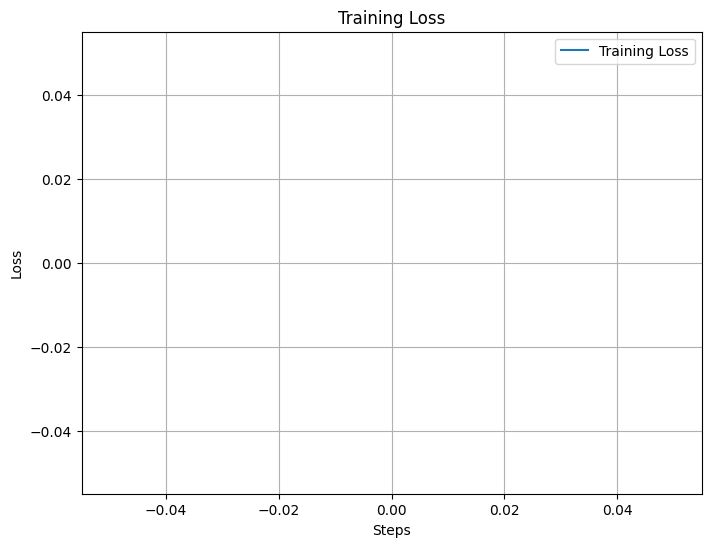

In [14]:
#(2.5) ToDo: Write the code to plot the Loss function

import matplotlib.pyplot as plt
plt.figure(figsize=(8, 6))
plt.plot(losses, label='Training Loss')
plt.title('Training Loss')
plt.xlabel('Steps')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

![steps1-5](steps1-5.png)

\# (3pts) ToDo: Draw the architecture of the neuralnetwork that we developed above and upload the picture in this text area. You can use powerpoint to create the image. You can also hand-draw the neural network and then, take a photo. Attach the image using the 'insert image' icon that is appearing just above this text area. Your image must show the layers and number of neurons and their connection in each layer.

**Create the new neural network**

Loss at step 0: 0.3726
Loss at step 1: 0.3671
Loss at step 2: 0.3618
Loss at step 3: 0.3567
Loss at step 4: 0.3519
Loss at step 5: 0.3472
Loss at step 6: 0.3427
Loss at step 7: 0.3384
Loss at step 8: 0.3342
Loss at step 9: 0.3303
Loss at step 10: 0.3264
Loss at step 11: 0.3228
Loss at step 12: 0.3192
Loss at step 13: 0.3159
Loss at step 14: 0.3126
Loss at step 15: 0.3095
Loss at step 16: 0.3065
Loss at step 17: 0.3036
Loss at step 18: 0.3008
Loss at step 19: 0.2982
Loss at step 20: 0.2956
Loss at step 21: 0.2932
Loss at step 22: 0.2908
Loss at step 23: 0.2886
Loss at step 24: 0.2864
Loss at step 25: 0.2843
Loss at step 26: 0.2823
Loss at step 27: 0.2804
Loss at step 28: 0.2785
Loss at step 29: 0.2768
Loss at step 30: 0.2751
Loss at step 31: 0.2734
Loss at step 32: 0.2719
Loss at step 33: 0.2704
Loss at step 34: 0.2689
Loss at step 35: 0.2675
Loss at step 36: 0.2662
Loss at step 37: 0.2649
Loss at step 38: 0.2637
Loss at step 39: 0.2625
Loss at step 40: 0.2613
Loss at step 41: 0.2602
Lo

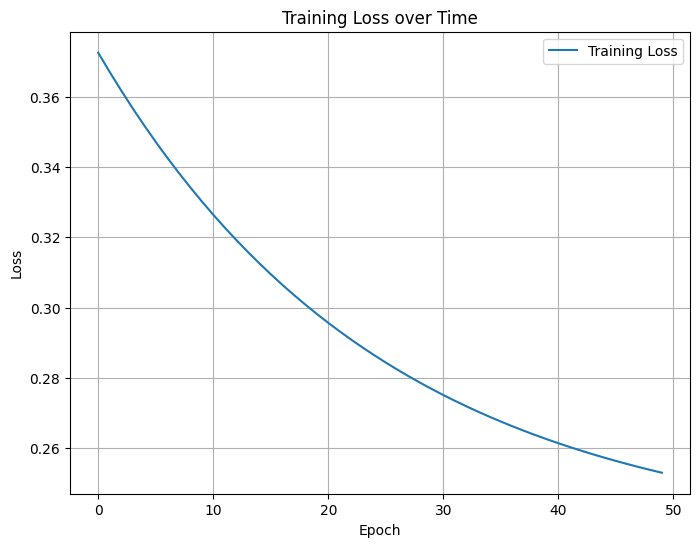

In [15]:
#(10pts) ToDO: Create a new neural network with the following architecture:
# One input layer, three hidden layers (layer0, layer1, layer2), and one output layer
input_size = 2 # Inputs: I2, I3
layer0_size = 2
layer1_size = 3
layer2_size = 2
output_neurons = 1

# Initialize the weights and biases for each layer
W0 = tf.Variable(tf.random.normal([input_size, layer0_size]), dtype=tf.float32)
b0 = tf.Variable(tf.zeros([layer0_size]), dtype=tf.float32)

W1 = tf.Variable(tf.random.normal([layer0_size, layer1_size]), dtype=tf.float32)
b1 = tf.Variable(tf.zeros([layer1_size]), dtype=tf.float32)

W2 = tf.Variable(tf.random.normal([layer1_size, layer2_size]), dtype=tf.float32)
b2 = tf.Variable(tf.zeros([layer2_size]), dtype=tf.float32)

W_out = tf.Variable(tf.random.normal([layer2_size, output_neurons]), dtype=tf.float32)
b_out = tf.Variable(tf.zeros([output_neurons]), dtype=tf.float32)

# Define ReLU activation function
def relu(x):
    return tf.maximum(0, x)

# Define the forward pass function
def forward_pass(inputs):
    # Layer 0
    layer0_output = relu(tf.matmul(inputs, W0) + b0)
    
    # Layer 1
    layer1_output = relu(tf.matmul(layer0_output, W1) + b1)
    
    # Layer 2
    layer2_output = relu(tf.matmul(layer1_output, W2) + b2)
    
    # Output layer (no activation)
    output = tf.matmul(layer2_output, W_out) + b_out
    return output

# Define the MSE loss function
def mse_loss(y_true, y_pred):
    return tf.reduce_mean(tf.square(y_true - y_pred))

# Training step
learning_rate = 0.01
def training_step(inputs, targets):
    with tf.GradientTape() as tape:
        predictions = forward_pass(inputs)
        loss = mse_loss(targets, predictions)
    gradients = tape.gradient(loss, [W0, b0, W1, b1, W2, b2, W_out, b_out])
    
    W0.assign_sub(learning_rate * gradients[0])
    b0.assign_sub(learning_rate * gradients[1])
    W1.assign_sub(learning_rate * gradients[2])
    b1.assign_sub(learning_rate * gradients[3])
    W2.assign_sub(learning_rate * gradients[4])
    b2.assign_sub(learning_rate * gradients[5])
    W_out.assign_sub(learning_rate * gradients[6])
    b_out.assign_sub(learning_rate * gradients[7])
    
    return loss

# Store the loss values for plotting
losses = []

# Train the neural network
epochs = 50
for step in range(epochs):
    loss = training_step(inputs, targets)
    losses.append(loss)
    print(f"Loss at step {step}: {loss:.4f}")

#(2.5pts) Plot the Loss function
plt.figure(figsize=(8, 6))
plt.plot(losses, label='Training Loss')
plt.title('Training Loss over Time')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True)
plt.legend()
plt.show()

**Submission instruction:**

You should submit the code through Google Colab.
Write/modify the code in Google Colab. Click 'Share' in the top-right corner. It will open a pop up window. In that pop up window, select 'Anyone with this link' from the dropdown instead of 'Restricted'. Then, select 'Editor' from the dropdown instead of 'viewer'. Then Click 'Copy link'. Paste that link on canvas for submission